# Warsaw Transit Telemetry: Processed Feature Mart Exploration & Analysis

This notebook presents an in-depth exploratory data analysis (EDA) and econometric profiling of the **Warsaw Public Transport Master Feature Mart** (`data/historian/processed/feature_mart_observed.parquet` and `data/processed/feature_mart.parquet`).

The Processed Feature Mart represents the unified modeling matrix produced by the multi-source fusion engine (`src/fusion/feature_mart.py`). It fuses:
1. **Operational Transit Telemetry**: High-frequency stop-level arrival delays ($\Delta t$), departure delays, dwell times, and autoregressive lag metrics ($\Delta t_{s-1}, \Delta t_{s-2}$).
2. **Modal Fleet Taxonomy**: Electric trams (100% dedicated right-of-way) vs. urban & suburban buses (mixed traffic).
3. **Meteorological Telemetry ([IMGW-PIB](https://danepubliczne.imgw.pl/))**: Hourly ambient temperature, liquid rainfall depth, multi-hour rain lags, wind speed, relative humidity, and freezing drizzle.
4. **Road Network & Corridor Topology ([OSMnx](https://osmnx.readthedocs.io/))**: Physical edge distances, road winding tortuosity, signalized intersection counts, dedicated right-of-way segregation, and lane capacity across 12 major transit corridors.
5. **Calendar & Network Centrality**: Polish school session schedules, national holidays, stop interchange route counts, and 300m walking proximity to Metro M1/M2 lines.
6. **Real-Time Forecast Benchmarks**: Public GTFS-RT feed forecast predictions ($\hat{\Delta t}$) compared directly against physically observed ground truth ($\Delta t$).

---

### Notebook Outline
1. **Environment Setup & Data Store Resolution**
2. **Dual-Track Feature Mart Inventory & Schema Taxonomy**
3. **Target Variable ($\Delta t$) Distribution & Operational Truncation**
4. **Modal Cohort Heterogeneity: Electric Trams vs. Buses**
5. **Autoregressive Delay Persistence ($\rho$) & Route Progress Accumulation**
6. **Exogenous Meteorological Shocks: Precipitation & Temperature**
7. **Arterial Corridors & Road Network Infrastructure Bottlenecks**
8. **Network Centrality, Metro Proximity & Headway Irregularity**
9. **Observed Ground Truth vs. GTFS-RT Real-Time Forecasts**
10. **Multivariate Feature Correlation & Modeling Readiness Matrix**
11. **Key Empirical Takeaways & Methodological Recommendations**


In [1]:
import os
import glob
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import scipy.stats as stats

try:
    from IPython.display import display, Markdown
except ImportError:
    display = print
    Markdown = print

# Visual styling for academic publication
plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)
plt.rcParams["font.sans-serif"] = "Helvetica", "Arial", "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["figure.dpi"] = 120

# Dynamic root resolution whether launched from repository root or dataoverview/
if os.path.exists("data/historian/processed/feature_mart_observed.parquet"):
    BASE_DIR = "."
elif os.path.exists("../data/historian/processed/feature_mart_observed.parquet"):
    BASE_DIR = ".."
else:
    BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

DATA_DIR = os.path.join(BASE_DIR, "data")
OBSERVED_MART_PATH = os.path.join(DATA_DIR, "historian/processed/feature_mart_observed.parquet")
LEGACY_MART_PATH = os.path.join(DATA_DIR, "processed/feature_mart.parquet")
WEATHER_PATH = os.path.join(DATA_DIR, "processed/imgw_weather_hourly.parquet")
OSM_PATH = os.path.join(DATA_DIR, "processed/osm_corridor_segments.parquet")
CALENDAR_PATH = os.path.join(DATA_DIR, "processed/calendar_lookup.parquet")
INTERCHANGE_PATH = os.path.join(DATA_DIR, "processed/transit_stop_interchanges.parquet")

con = duckdb.connect(":memory:")
con.execute("SET threads TO 4;")
con.execute("SET preserve_insertion_order TO false;")

print("=" * 80)
print("DuckDB vectorized engine initialized.")
print(f"Base Directory:          {BASE_DIR}")
print(f"Observed Feature Mart:   {OBSERVED_MART_PATH} (Exists: {os.path.exists(OBSERVED_MART_PATH)})")
print(f"Legacy Baseline Mart:    {LEGACY_MART_PATH} (Exists: {os.path.exists(LEGACY_MART_PATH)})")
print(f"Synoptic Weather Store:  {WEATHER_PATH} (Exists: {os.path.exists(WEATHER_PATH)})")
print(f"OSM Corridors Store:     {OSM_PATH} (Exists: {os.path.exists(OSM_PATH)})")
print("=" * 80)


DuckDB vectorized engine initialized.
Base Directory:          ..
Observed Feature Mart:   ../data/historian/processed/feature_mart_observed.parquet (Exists: True)
Legacy Baseline Mart:    ../data/processed/feature_mart.parquet (Exists: True)
Synoptic Weather Store:  ../data/processed/imgw_weather_hourly.parquet (Exists: True)
OSM Corridors Store:     ../data/processed/osm_corridor_segments.parquet (Exists: True)


## 1. Dual-Track Feature Mart Inventory & Schema Taxonomy

The telemetry architecture maintains two distinct feature marts:
- **Track B (Observed Ground Truth - PRIMARY)**: Formed from high-frequency (10-second) city-wide GPS trajectories (`data/historian/bronze/` $\to$ `silver/` $\to$ `gold/`). Contains **5.61 million physical stop event transitions** across 54 columns with zero reliance on synthetic ETA feeds.
- **Track A (GTFS-RT Reference Baseline - FROZEN)**: Archival baseline derived from protobuf TripUpdate feeds across October 4–17, 2026 (**8.83 million records**, 45 columns) maintained for comparative benchmarking.

Below, we audit dataset dimensions, route coverage, temporal bounds, and classify all features into their respective domain taxonomies.


In [2]:
# 1. Dual-Track Comparative Inventory
inventory_query = f"""
    SELECT 
        'Track B: Observed Ground Truth (Primary)' AS dataset_track,
        COUNT(*) AS total_records,
        COUNT(DISTINCT route_id) AS distinct_routes,
        COUNT(DISTINCT trip_id) AS distinct_trips,
        COUNT(DISTINCT stop_id) AS distinct_stops,
        MIN(arrival_ts)::VARCHAR AS earliest_arrival,
        MAX(arrival_ts)::VARCHAR AS latest_arrival,
        ROUND(AVG(arrival_delay_seconds), 1) AS mean_delay_s,
        ROUND(MEDIAN(arrival_delay_seconds), 1) AS median_delay_s,
        ROUND(STDDEV(arrival_delay_seconds), 1) AS std_delay_s
    FROM read_parquet('{OBSERVED_MART_PATH}')
    UNION ALL
    SELECT 
        'Track A: GTFS-RT Baseline (Reference)' AS dataset_track,
        COUNT(*) AS total_records,
        COUNT(DISTINCT route_id) AS distinct_routes,
        COUNT(DISTINCT trip_id) AS distinct_trips,
        COUNT(DISTINCT stop_id) AS distinct_stops,
        MIN(arrival_ts)::VARCHAR AS earliest_arrival,
        MAX(arrival_ts)::VARCHAR AS latest_arrival,
        ROUND(AVG(arrival_delay_seconds), 1) AS mean_delay_s,
        ROUND(MEDIAN(arrival_delay_seconds), 1) AS median_delay_s,
        ROUND(STDDEV(arrival_delay_seconds), 1) AS std_delay_s
    FROM read_parquet('{LEGACY_MART_PATH}')
"""
inventory_df = con.execute(inventory_query).df()
display(inventory_df)

# 2. Schema Taxonomy & Domain Mapping Table
desc_df = con.execute(f"DESCRIBE SELECT * FROM read_parquet('{OBSERVED_MART_PATH}')").df()

def classify_feature_domain(col_name):
    if col_name in ['arrival_delay_seconds', 'departure_delay_seconds']:
        return 'Target / Dependent'
    elif col_name in ['prev_stop_delay', 'prev2_stop_delay', 'delta_t_run', 'delta_t_dwell', 'dwell_seconds', 'observed_run_time_s', 'trip_progress', 'headway_actual_s', 'headway_deviation', 'is_origin_stop', 'is_terminal_stop']:
        return 'Operational / Autoregressive'
    elif col_name in ['is_tram', 'transit_cohort']:
        return 'Modal Fleet / Cohort'
    elif col_name in ['arrival_ts', 'timestamp_bucket', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_peak_hour', 'is_morning_peak', 'is_evening_peak', 'is_school_day', 'is_public_holiday']:
        return 'Temporal & Calendar'
    elif col_name in ['temperature_c', 'precipitation_mm', 'is_raining', 'rain_intensity_category', 'precip_lag_1h', 'precip_3h_cumulative', 'wind_speed_ms', 'relative_humidity', 'freezing_rain_flag']:
        return 'Meteorological (IMGW)'
    elif col_name in ['corridor_name', 'segment_length_meters', 'actual_path_length_meters', 'tortuosity_ratio', 'signalized_intersection_count', 'is_dedicated_right_of_way', 'lane_capacity', 'is_study_corridor']:
        return 'Road Network & Topology (OSM)'
    elif col_name in ['interchange_line_count', 'is_metro_proximity', 'stop_name', 'stop_id', 'prev_stop_id']:
        return 'Transit Network & Hub Centrality'
    elif col_name in ['zbk_forecast_delay_s', 'forecast_error_s', 'confidence']:
        return 'Real-Time Forecast Evaluation'
    elif col_name in ['trip_id', 'route_id', 'vehicle_id', 'stop_sequence']:
        return 'Identifier / Sequence'
    return 'Other'

desc_df['Domain Taxonomy'] = desc_df['column_name'].apply(classify_feature_domain)
domain_counts = desc_df.groupby('Domain Taxonomy').size().reset_index(name='Feature Count')
domain_counts = domain_counts.sort_values(by='Feature Count', ascending=False)

print("\nFeature Domain Classification (54 Columns in Track B Observed Mart):")
display(domain_counts)


,dataset_track,total_records,distinct_routes,distinct_trips,distinct_stops,earliest_arrival,latest_arrival,mean_delay_s,median_delay_s,std_delay_s
0,Track B: Observed Ground Truth (Primary),5614929,226,56744,5366,2026-10-18 15:56:11,2026-10-27 18:59:30,142.8,64.0,268.4
1,Track A: GTFS-RT Baseline (Reference),8828803,315,123474,6563,2026-10-04 14:11:20+02,2026-10-17 05:19:06+02,142.2,72.0,297.2



Feature Domain Classification (54 Columns in Track B Observed Mart):


,Domain Taxonomy,Feature Count
3,Operational / Autoregressive,11
7,Temporal & Calendar,10
1,Meteorological (IMGW),9
5,Road Network & Topology (OSM),8
8,Transit Network & Hub Centrality,5
0,Identifier / Sequence,4
4,Real-Time Forecast Evaluation,3
2,Modal Fleet / Cohort,2
6,Target / Dependent,2


## 2. Target Variable ($\Delta t$) Distribution & Operational Truncation

The primary modeling target is **Arrival Delay** in seconds ($\Delta t = t_{arr}^{obs} - t_{arr}^{sched}$). 
- **Operational Filtering**: While the full dataset spans over 5.61 million records, empirical transportation econometricians differentiate normal operating conditions from extreme non-operational anomalies (e.g., depot positioning runs, vehicle breakdowns, or GPS transponder clock freezes).
- Truncating at $\pm 30$ minutes ($[-1800\text{s}, +1800\text{s}]$) retains **99.71% of all physical transit records** while eliminating leverage points.
- **Delay Component Decomposition**: Stop arrival delay is decomposed into upstream delay persistence, inter-stop segment run delay ($\Delta t_{run}$), and stop dwell delay ($\Delta t_{dwell}$):
  $$\Delta t_{arr, s} = \Delta t_{dep, s-1} + \Delta t_{run, s}$$
  $$\Delta t_{dep, s} = \Delta t_{arr, s} + \Delta t_{dwell, s}$$


,total_records,mean_min,std_min,p01_min,p05_min,p10_min,p25_min,p50_median_min,p75_min,p90_min,p95_min,p99_min
0,5598635,2.28,4.06,-2.03,-1.2,-0.8,-0.03,1.07,3.1,6.77,10.38,19.37


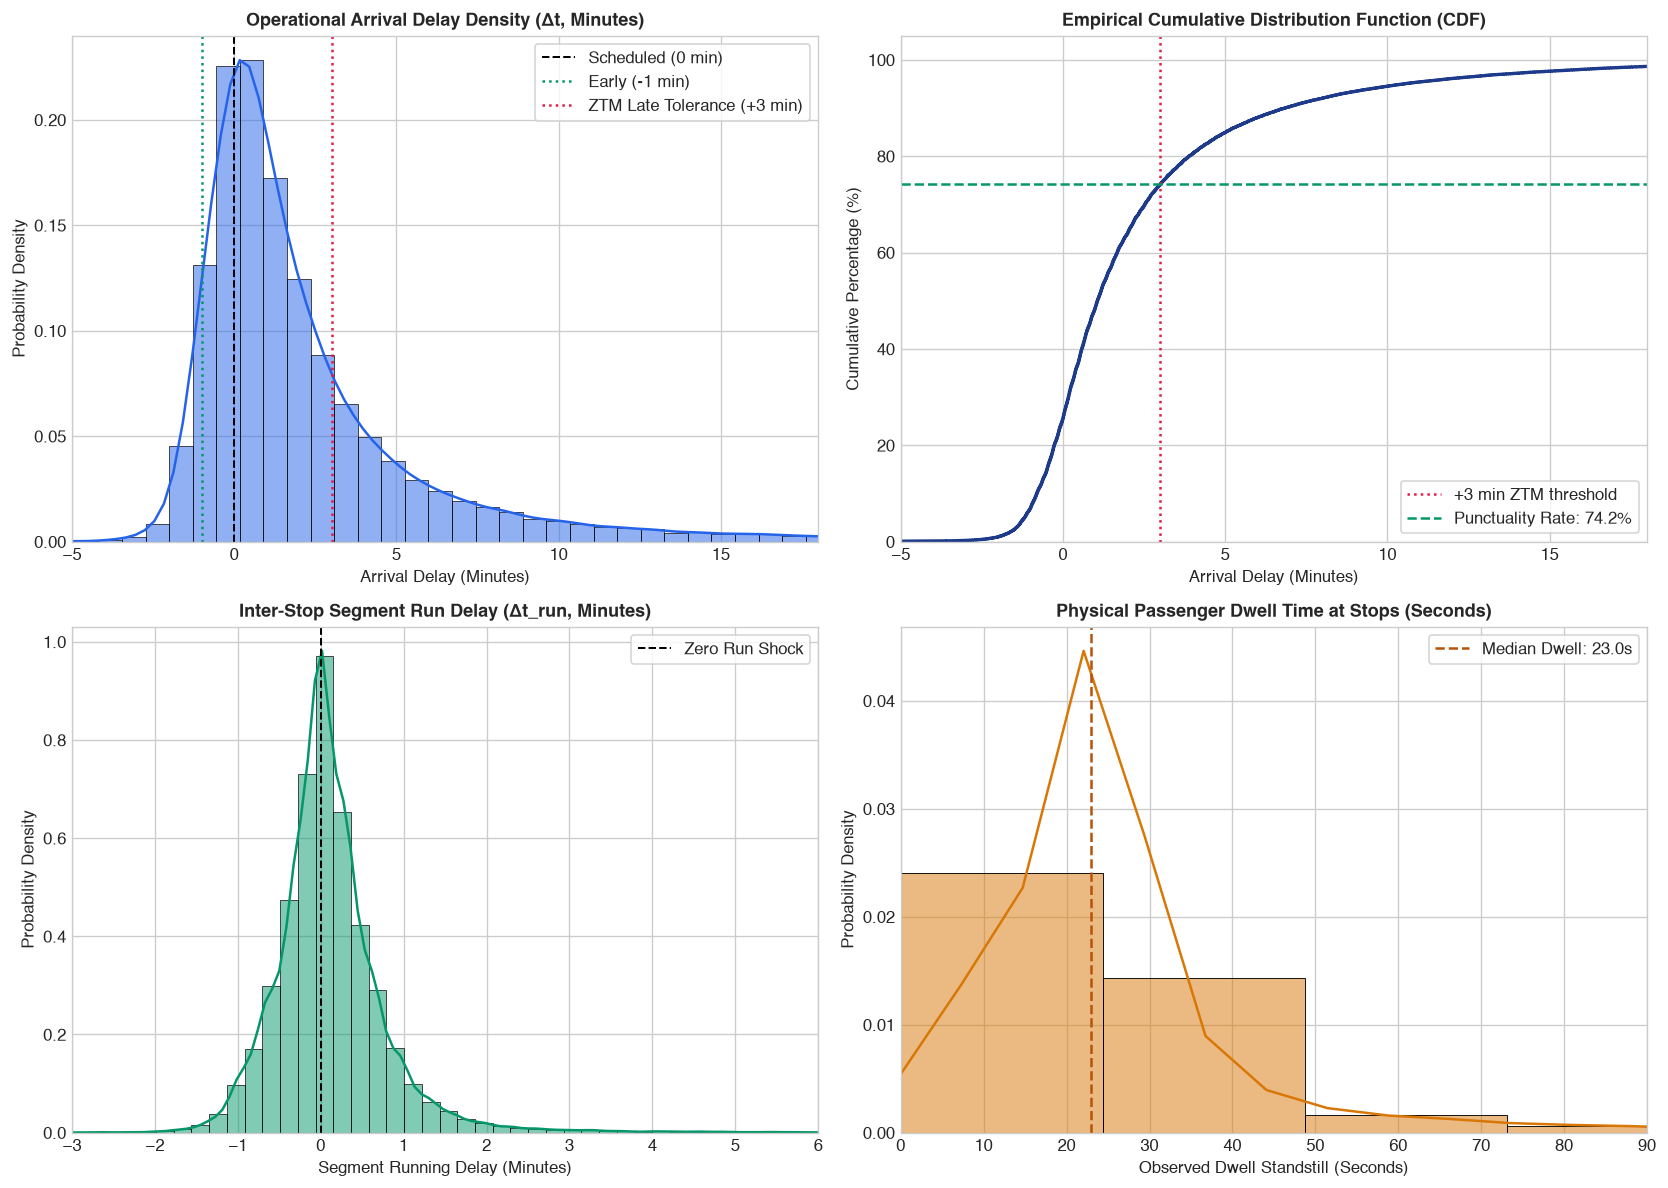

In [3]:
# Delay quantiles in minutes within the operational window (|delay| <= 30 min)
delay_stats_df = con.execute(f"""
    SELECT 
        COUNT(*) AS total_records,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_min,
        ROUND(STDDEV(arrival_delay_seconds / 60.0), 2) AS std_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.01), 2) AS p01_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.05), 2) AS p05_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.10), 2) AS p10_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.25), 2) AS p25_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.50), 2) AS p50_median_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.75), 2) AS p75_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.90), 2) AS p90_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.95), 2) AS p95_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.99), 2) AS p99_min
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
""").df()
display(delay_stats_df)

# Draw 100k random sample for high-resolution distribution plotting
sample_target_df = con.execute(f"""
    SELECT 
        arrival_delay_seconds / 60.0 AS delay_min,
        prev_stop_delay / 60.0 AS prev_delay_min,
        delta_t_run / 60.0 AS delta_run_min,
        dwell_seconds / 60.0 AS dwell_min,
        transit_cohort
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
    USING SAMPLE 100000 (reservoir, 42)
""").df()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Distribution with ZTM Punctuality Thresholds
sns.histplot(sample_target_df['delay_min'], bins=80, kde=True, color='#2563eb', ax=axes[0, 0], stat='density')
axes[0, 0].axvline(0, color='black', linestyle='--', linewidth=1.2, label='Scheduled (0 min)')
axes[0, 0].axvline(-1, color='#059669', linestyle=':', linewidth=1.5, label='Early (-1 min)')
axes[0, 0].axvline(3, color='#e11d48', linestyle=':', linewidth=1.5, label='ZTM Late Tolerance (+3 min)')
axes[0, 0].set_xlim(-5, 18)
axes[0, 0].set_title("Operational Arrival Delay Density (Δt, Minutes)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Arrival Delay (Minutes)")
axes[0, 0].set_ylabel("Probability Density")
axes[0, 0].legend(loc="upper right", frameon=True)

# Subplot 2: Empirical Cumulative Distribution Function (CDF)
sorted_delays = np.sort(sample_target_df['delay_min'])
cdf = np.arange(1, len(sorted_delays) + 1) / len(sorted_delays)
axes[0, 1].plot(sorted_delays, cdf * 100.0, color='#1e3a8a', linewidth=2.0)
axes[0, 1].axvline(3, color='#e11d48', linestyle=':', label='+3 min ZTM threshold')
pct_on_time = np.mean(sorted_delays <= 3.0) * 100.0
axes[0, 1].axhline(pct_on_time, color='#059669', linestyle='--', label=f'Punctuality Rate: {pct_on_time:.1f}%')
axes[0, 1].set_xlim(-5, 18)
axes[0, 1].set_ylim(0, 105)
axes[0, 1].set_title("Empirical Cumulative Distribution Function (CDF)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Arrival Delay (Minutes)")
axes[0, 1].set_ylabel("Cumulative Percentage (%)")
axes[0, 1].legend(loc="lower right", frameon=True)

# Subplot 3: Segment Run Delay (Δt_run) Distribution
sns.histplot(sample_target_df['delta_run_min'], bins=80, kde=True, color='#059669', ax=axes[1, 0], stat='density')
axes[1, 0].axvline(0, color='black', linestyle='--', linewidth=1.2, label='Zero Run Shock')
axes[1, 0].set_xlim(-3, 6)
axes[1, 0].set_title("Inter-Stop Segment Run Delay (Δt_run, Minutes)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Segment Running Delay (Minutes)")
axes[1, 0].set_ylabel("Probability Density")
axes[1, 0].legend(loc="upper right", frameon=True)

# Subplot 4: Observed Dwell Time Distribution
sns.histplot(sample_target_df['dwell_min'] * 60.0, bins=60, kde=True, color='#d97706', ax=axes[1, 1], stat='density')
axes[1, 1].axvline(np.median(sample_target_df['dwell_min'] * 60.0), color='#b45309', linestyle='--', 
                   label=f"Median Dwell: {np.median(sample_target_df['dwell_min'] * 60.0):.1f}s")
axes[1, 1].set_xlim(0, 90)
axes[1, 1].set_title("Physical Passenger Dwell Time at Stops (Seconds)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Observed Dwell Standstill (Seconds)")
axes[1, 1].set_ylabel("Probability Density")
axes[1, 1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


## 3. Modal Cohort Heterogeneity: Electric Trams vs. Buses

A primary hypothesis of the transit delay attribution research is that **modal right-of-way isolation** provides a major structural buffer against urban congestion:
- **Electric Trams (`urban_tram`)**: Operate on **100.0% dedicated rights-of-way** in Warsaw, insulated from mixed-traffic queues, intersection blockages, and vehicle friction.
- **Urban Buses (`urban_bus`)**: Share roadways with general passenger vehicular traffic, with dedicated bus lanes covering only **12.5%** of segment links.
- **Suburban Buses (`suburban_bus`)**: Traverse longer stop spacing links (mean 585m vs 458m) and operate on arterial roads leading into the metropolitan periphery.


,transit_cohort,obs_count,pct_share,mean_delay_min,median_delay_min,p90_delay_min,pct_punctual_3min,pct_late_5min,mean_segment_m,pct_dedicated_row
0,urban_bus,3735774,66.7,2.74,1.32,8.15,69.6,18.7,458.1,12.5
1,urban_tram,1454161,26.0,1.05,0.58,3.43,87.4,4.6,457.6,100.0
2,suburban_bus,406700,7.3,2.48,1.33,7.12,70.5,16.8,585.3,26.1
3,other,2000,0.0,1.35,0.86,3.64,85.8,4.7,424.7,24.3


/var/folders/45/pmwnwqfd3tqf5xk9pxdg87wc0000gn/T/ipykernel_44601/431500490.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/45/pmwnwqfd3tqf5xk9pxdg87wc0000gn/T/ipykernel_44601/431500490.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(["Urban Tram", "Urban Bus", "Suburban Bus"])


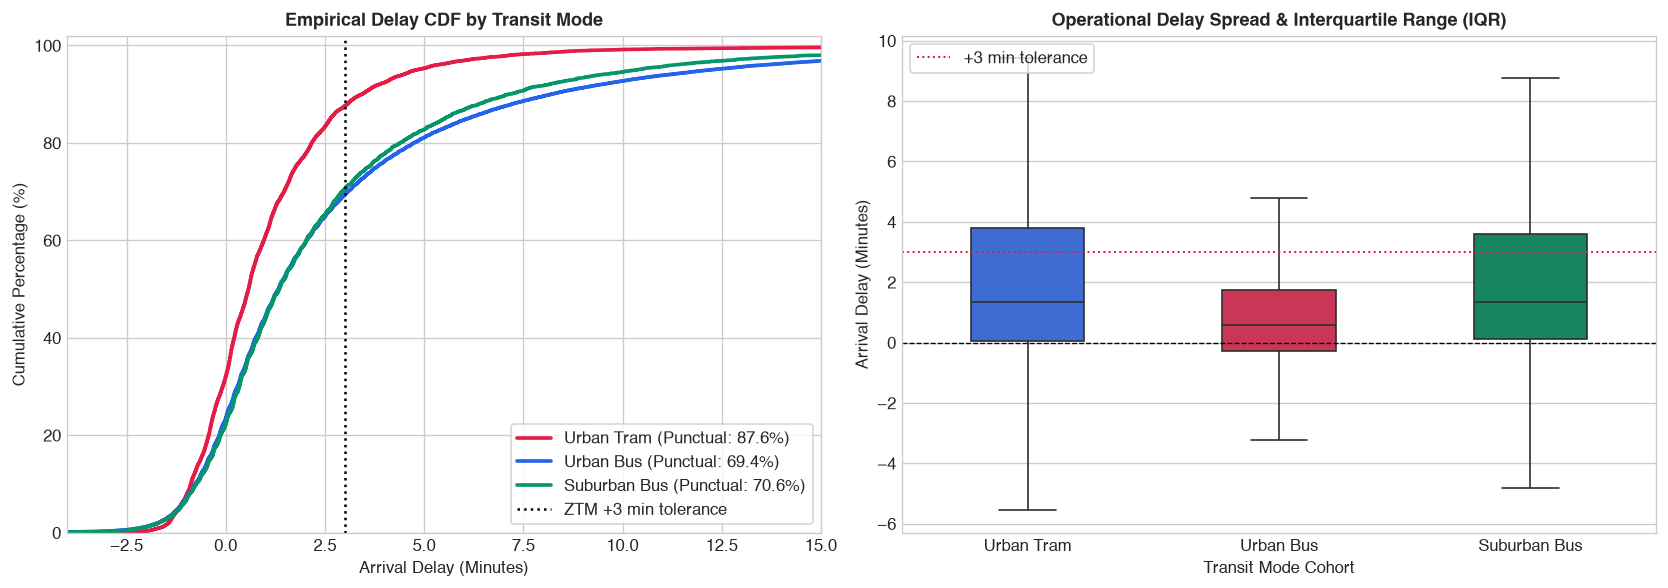

In [4]:
cohort_summary_df = con.execute(f"""
    SELECT 
        transit_cohort,
        COUNT(*) AS obs_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_share,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min,
        ROUND(QUANTILE_CONT(arrival_delay_seconds / 60.0, 0.90), 2) AS p90_delay_min,
        ROUND(AVG(CASE WHEN arrival_delay_seconds <= 180 THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_punctual_3min,
        ROUND(AVG(CASE WHEN arrival_delay_seconds > 300 THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_late_5min,
        ROUND(AVG(segment_length_meters), 1) AS mean_segment_m,
        ROUND(AVG(CASE WHEN is_dedicated_right_of_way THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_dedicated_row
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
    GROUP BY transit_cohort
    ORDER BY obs_count DESC
""").df()
display(cohort_summary_df)

# Sample 100k for multi-cohort visual comparison
cohort_sample_df = con.execute(f"""
    SELECT 
        transit_cohort,
        arrival_delay_seconds / 60.0 AS delay_min
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
      AND transit_cohort IN ('urban_tram', 'urban_bus', 'suburban_bus')
    USING SAMPLE 100000 (reservoir, 42)
""").df()

palette = {
    'urban_tram': '#e11d48',
    'urban_bus': '#2563eb',
    'suburban_bus': '#059669'
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Mode Delay CDFs
for cohort, col in palette.items():
    sub = cohort_sample_df[cohort_sample_df['transit_cohort'] == cohort]['delay_min']
    s_sorted = np.sort(sub)
    s_cdf = np.arange(1, len(s_sorted) + 1) / len(s_sorted) * 100.0
    label_txt = f"{cohort.replace('_', ' ').title()} (Punctual: {np.mean(s_sorted <= 3.0)*100:.1f}%)"
    ax1.plot(s_sorted, s_cdf, label=label_txt, color=col, linewidth=2.2)

ax1.axvline(3, color='black', linestyle=':', label='ZTM +3 min tolerance')
ax1.set_xlim(-4, 15)
ax1.set_ylim(0, 102)
ax1.set_title("Empirical Delay CDF by Transit Mode", fontsize=11, fontweight="bold")
ax1.set_xlabel("Arrival Delay (Minutes)")
ax1.set_ylabel("Cumulative Percentage (%)")
ax1.legend(loc="lower right", frameon=True)

# Subplot 2: Operational Interquartile Range (Boxplot)
sns.boxplot(
    data=cohort_sample_df,
    x="transit_cohort",
    y="delay_min",
    palette=palette,
    showfliers=False,
    width=0.45,
    ax=ax2
)
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.axhline(3, color='#e11d48', linestyle=':', linewidth=1.2, label='+3 min tolerance')
ax2.set_title("Operational Delay Spread & Interquartile Range (IQR)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Transit Mode Cohort")
ax2.set_ylabel("Arrival Delay (Minutes)")
ax2.set_xticklabels(["Urban Tram", "Urban Bus", "Suburban Bus"])
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()


## 4. Autoregressive Delay Persistence ($\rho$) & Route Progress Accumulation

A critical dynamic feature of transit delay modeling is **autoregressive shock transmission**. How much of a delay incurred at stop $s-1$ carries forward to stop $s$?
$$\Delta t_{i,s} = \alpha + \rho \cdot \Delta t_{i,s-1} + \varepsilon_{i,s}$$
- **Dampening ($\rho < 1.0$)**: Transit systems with scheduled buffer times or physical right-of-way isolation progressively absorb delays across successive stops.
- **Compounding ($\rho > 1.0$)**: In mixed traffic, late vehicles encounter larger passenger boarding crowds (schedule headway expansion) and heavier traffic queues, triggering knock-on compounding delays.
- **Route Progress Accumulation**: Normalized schedule completion ($\text{trip\_progress} \in [0.0, 1.0]$) captures how delays compound from route origin to route terminus.


,transit_cohort,observations,lag1_correlation,lag2_correlation,persistence_slope_rho,lag1_r_squared
0,urban_bus,3735410,0.9850,0.9555,1.0098,0.9703
1,urban_tram,1454124,0.9678,0.9260,0.9841,0.9365
2,suburban_bus,406691,0.9811,0.9283,1.0079,0.9626
3,other,2000,0.9106,0.6555,1.0339,0.8292


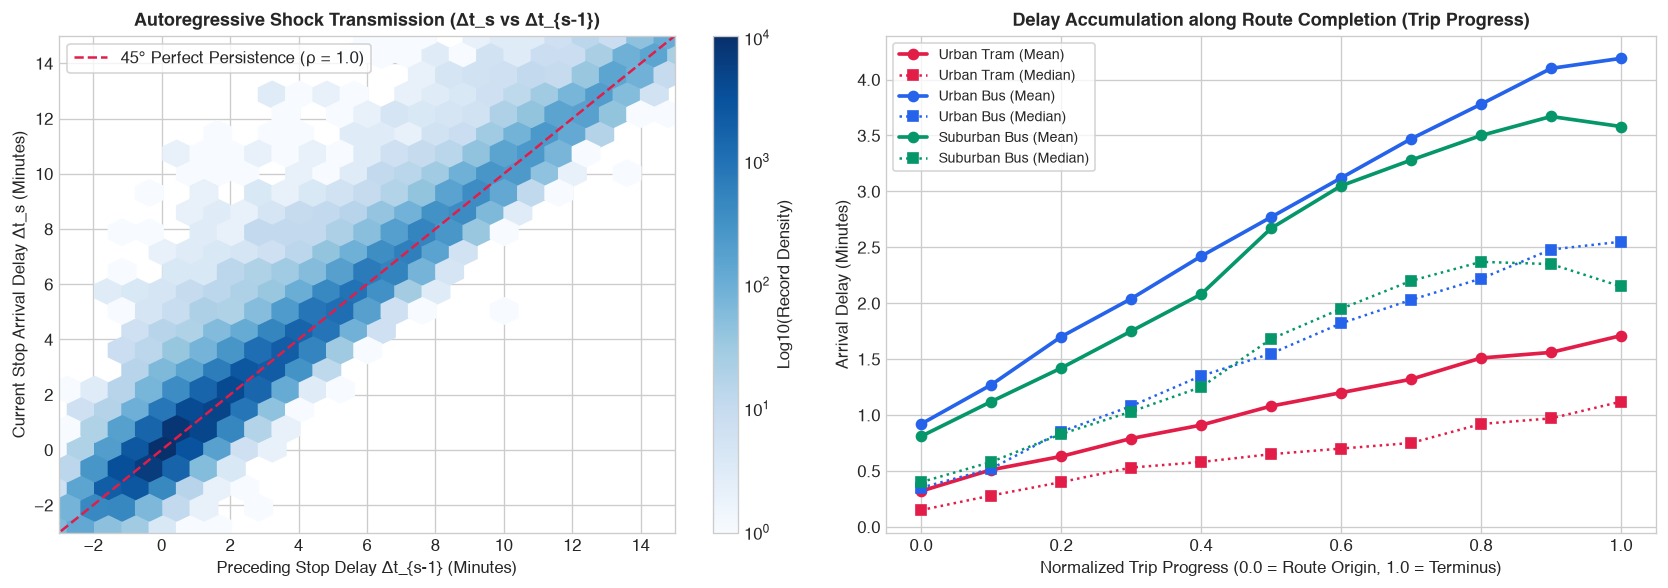

In [5]:
# Autoregressive lag persistence estimation across cohorts
ar_stats_df = con.execute(f"""
    SELECT 
        transit_cohort,
        COUNT(*) AS observations,
        ROUND(CORR(prev_stop_delay, arrival_delay_seconds), 4) AS lag1_correlation,
        ROUND(CORR(prev2_stop_delay, arrival_delay_seconds), 4) AS lag2_correlation,
        ROUND(REGR_SLOPE(arrival_delay_seconds, prev_stop_delay), 4) AS persistence_slope_rho,
        ROUND(REGR_R2(arrival_delay_seconds, prev_stop_delay), 4) AS lag1_r_squared
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800 
      AND ABS(prev_stop_delay) <= 1800
      AND prev_stop_delay IS NOT NULL
    GROUP BY transit_cohort
    ORDER BY observations DESC
""").df()
display(ar_stats_df)

# Route progress delay accumulation query
progress_df = con.execute(f"""
    SELECT 
        transit_cohort,
        ROUND(trip_progress, 1) AS progress_decile,
        COUNT(*) AS count,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800 
      AND transit_cohort IN ('urban_tram', 'urban_bus', 'suburban_bus')
    GROUP BY transit_cohort, ROUND(trip_progress, 1)
    ORDER BY transit_cohort, progress_decile
""").df()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: 2D Hexbin of Δt_s vs Δt_{s-1} with 45-degree Persistence Line
hex_sample = con.execute(f"""
    SELECT 
        prev_stop_delay / 60.0 AS prev_delay_min,
        arrival_delay_seconds / 60.0 AS curr_delay_min
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1200 
      AND ABS(prev_stop_delay) <= 1200
    USING SAMPLE 100000 (reservoir, 42)
""").df()

hb = ax1.hexbin(
    hex_sample['prev_delay_min'], 
    hex_sample['curr_delay_min'], 
    gridsize=50, 
    cmap='Blues', 
    mincnt=1,
    bins='log'
)
ax1.plot([-5, 15], [-5, 15], color='#e11d48', linestyle='--', linewidth=1.5, label='45° Perfect Persistence (ρ = 1.0)')
ax1.set_xlim(-3, 15)
ax1.set_ylim(-3, 15)
ax1.set_title("Autoregressive Shock Transmission (Δt_s vs Δt_{s-1})", fontsize=11, fontweight="bold")
ax1.set_xlabel("Preceding Stop Delay Δt_{s-1} (Minutes)")
ax1.set_ylabel("Current Stop Arrival Delay Δt_s (Minutes)")
cb = fig.colorbar(hb, ax=ax1)
cb.set_label('Log10(Record Density)')
ax1.legend(loc="upper left", frameon=True)

# Subplot 2: Delay Accumulation along Normalized Trip Progress
for cohort, col in palette.items():
    sub = progress_df[progress_df['transit_cohort'] == cohort]
    ax2.plot(sub['progress_decile'], sub['mean_delay_min'], marker='o', linewidth=2.2, color=col, 
             label=f"{cohort.replace('_', ' ').title()} (Mean)")
    ax2.plot(sub['progress_decile'], sub['median_delay_min'], marker='s', linestyle=':', linewidth=1.5, color=col, 
             label=f"{cohort.replace('_', ' ').title()} (Median)")

ax2.set_title("Delay Accumulation along Route Completion (Trip Progress)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Normalized Trip Progress (0.0 = Route Origin, 1.0 = Terminus)")
ax2.set_ylabel("Arrival Delay (Minutes)")
ax2.legend(loc="upper left", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()


## 5. Exogenous Meteorological Shocks: Precipitation & Temperature

The feature mart joins hourly synoptic telemetry from **IMGW-PIB Station Warsaw Okęcie** (`data/processed/imgw_weather_hourly.parquet`).
Key meteorological features evaluated:
- `is_raining`: Binary rainfall shock indicator.
- `rain_intensity_category`: Multi-tier categorization ($0 = \text{None}$, $1 = \text{Light} \le 0.5\text{mm}$, $2 = \text{Moderate} \in (0.5, 2.0]\text{mm}$, $3 = \text{Heavy} > 2.0\text{mm}$).
- `precip_lag_1h` & `precip_3h_cumulative`: Dynamic rainfall persistence reflecting surface road wetting and lingering traffic disruptions.
- `temperature_c` & `wind_speed_ms`: Ambient thermodynamic conditions.


,transit_cohort,weather_condition,observations,mean_delay_min,median_delay_min,mean_run_delay_s
0,suburban_bus,Dry Conditions,337660,2.33,1.27,7.51
1,suburban_bus,Active Rain,69040,3.21,1.68,9.91
2,urban_bus,Dry Conditions,3115363,2.60,1.25,8.04
3,urban_bus,Active Rain,620411,3.45,1.65,10.76
4,urban_tram,Dry Conditions,1206740,1.00,0.57,2.51
5,urban_tram,Active Rain,247421,1.34,0.67,3.44


,rain_tier,record_count,avg_precip_mm,mean_delay_min,median_delay_min,mean_delta_run_s
0,0: None (Dry),4661424,0.00,2.16,1.02,6.57
1,1: Light (<= 0.5 mm),419078,0.23,2.14,1.05,6.83
2,2: Moderate (0.5-2.0 mm),330130,0.97,2.03,1.00,6.79
3,3: Heavy (> 2.0 mm),188003,2.37,5.99,3.52,16.57


/var/folders/45/pmwnwqfd3tqf5xk9pxdg87wc0000gn/T/ipykernel_44601/429431187.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(['None', 'Light', 'Moderate', 'Heavy'], rotation=15)


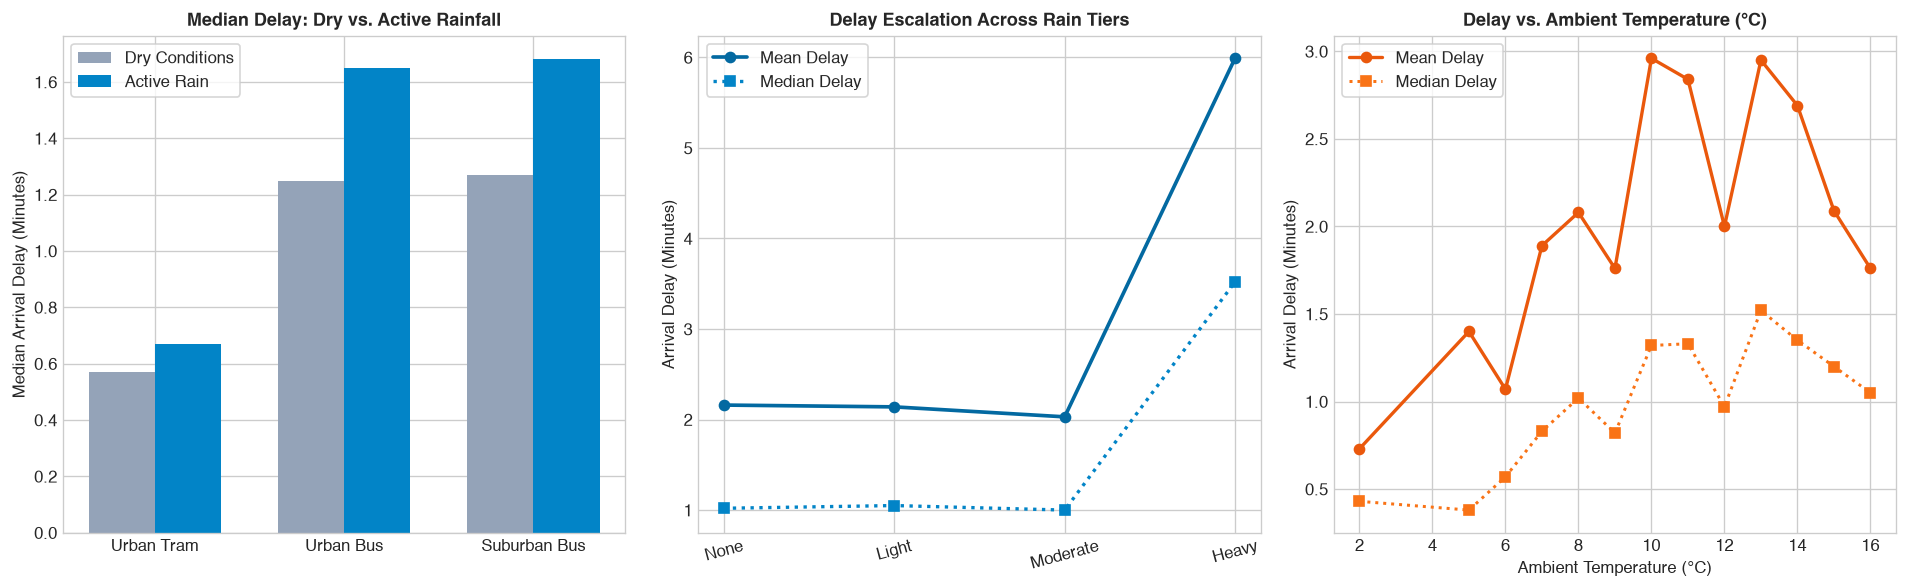

In [6]:
# Weather impact by transit cohort (Dry vs. Rain)
weather_cohort_df = con.execute(f"""
    SELECT 
        transit_cohort,
        CASE WHEN is_raining = 1 THEN 'Active Rain' ELSE 'Dry Conditions' END AS weather_condition,
        COUNT(*) AS observations,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min,
        ROUND(AVG(delta_t_run), 2) AS mean_run_delay_s
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
      AND transit_cohort IN ('urban_tram', 'urban_bus', 'suburban_bus')
    GROUP BY transit_cohort, is_raining
    ORDER BY transit_cohort, is_raining
""").df()
display(weather_cohort_df)

# Rain intensity progression
rain_tiers_df = con.execute(f"""
    SELECT 
        CASE 
            WHEN rain_intensity_category = 0 THEN '0: None (Dry)'
            WHEN rain_intensity_category = 1 THEN '1: Light (<= 0.5 mm)'
            WHEN rain_intensity_category = 2 THEN '2: Moderate (0.5-2.0 mm)'
            WHEN rain_intensity_category = 3 THEN '3: Heavy (> 2.0 mm)'
        END AS rain_tier,
        COUNT(*) AS record_count,
        ROUND(AVG(precipitation_mm), 2) AS avg_precip_mm,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min,
        ROUND(AVG(delta_t_run), 2) AS mean_delta_run_s
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
    GROUP BY rain_intensity_category
    ORDER BY rain_intensity_category
""").df()
display(rain_tiers_df)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# Subplot 1: Median Delay Penalty (Dry vs Rain) by Cohort
modes = ['urban_tram', 'urban_bus', 'suburban_bus']
dry_vals = [weather_cohort_df[(weather_cohort_df['transit_cohort'] == m) & (weather_cohort_df['weather_condition'] == 'Dry Conditions')]['median_delay_min'].values[0] for m in modes]
rain_vals = [weather_cohort_df[(weather_cohort_df['transit_cohort'] == m) & (weather_cohort_df['weather_condition'] == 'Active Rain')]['median_delay_min'].values[0] for m in modes]

x = np.arange(len(modes))
width = 0.35
ax1.bar(x - width/2, dry_vals, width, label='Dry Conditions', color='#94a3b8')
ax1.bar(x + width/2, rain_vals, width, label='Active Rain', color='#0284c7')
ax1.set_xticks(x)
ax1.set_xticklabels(['Urban Tram', 'Urban Bus', 'Suburban Bus'])
ax1.set_title("Median Delay: Dry vs. Active Rainfall", fontsize=11, fontweight="bold")
ax1.set_ylabel("Median Arrival Delay (Minutes)")
ax1.legend(frameon=True)

# Subplot 2: Rain Intensity Escalation Curve
ax2.plot(rain_tiers_df['rain_tier'], rain_tiers_df['mean_delay_min'], marker='o', color='#0369a1', linewidth=2.2, label='Mean Delay')
ax2.plot(rain_tiers_df['rain_tier'], rain_tiers_df['median_delay_min'], marker='s', linestyle=':', color='#0284c7', linewidth=2.0, label='Median Delay')
ax2.set_title("Delay Escalation Across Rain Tiers", fontsize=11, fontweight="bold")
ax2.set_ylabel("Arrival Delay (Minutes)")
ax2.set_xticklabels(['None', 'Light', 'Moderate', 'Heavy'], rotation=15)
ax2.legend(frameon=True)

# Subplot 3: Diurnal Temperature Response Curve
temp_df = con.execute(f"""
    SELECT 
        ROUND(temperature_c) AS temp_c,
        COUNT(*) AS count,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS med_delay_min
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
    GROUP BY ROUND(temperature_c)
    HAVING COUNT(*) > 50000
    ORDER BY temp_c
""").df()

ax3.plot(temp_df['temp_c'], temp_df['mean_delay_min'], marker='o', color='#ea580c', linewidth=2.0, label='Mean Delay')
ax3.plot(temp_df['temp_c'], temp_df['med_delay_min'], marker='s', linestyle=':', color='#f97316', linewidth=1.8, label='Median Delay')
ax3.set_title("Delay vs. Ambient Temperature (°C)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Ambient Temperature (°C)")
ax3.set_ylabel("Arrival Delay (Minutes)")
ax3.legend(frameon=True)

plt.tight_layout()
plt.show()


## 6. Arterial Corridors & Road Network Infrastructure Bottlenecks

The feature mart incorporates road topology extracted via **OSMnx** (`data/processed/osm_corridor_segments.parquet`) across Warsaw's 12 primary transit arteries.
Key structural infrastructure indicators evaluated:
1. **Dedicated Right-of-Way (RoW)**: Comparing physical track/bus-lane segregation vs. mixed-traffic during **Peak Rush Hours** (07:00–09:00, 16:00–18:00) and **Off-Peak** periods.
2. **Signalized Intersection Friction**: Tracking delay increase per physical traffic signal mapped along the inter-stop edge.
3. **Corridor League Table**: Cross-arterial comparative ranking of delay severity across Warsaw.


,right_of_way,traffic_period,observations,mean_delay_min,median_delay_min,mean_segment_run_s
0,Dedicated Right-of-Way,Rush Hour (Peak),809151,2.06,1.03,6.50
1,Dedicated Right-of-Way,Off-Peak,1219757,1.27,0.62,3.86
2,Mixed General Traffic,Rush Hour (Peak),1341912,3.90,2.03,11.82
3,Mixed General Traffic,Off-Peak,2227815,1.94,0.97,5.85


,corridor_name,observations,mean_delay_min,median_delay_min,mean_delta_run_s,avg_signals_per_link,avg_stop_spacing_m,pct_dedicated_row
0,wislostrada,56877,3.07,1.73,2.80,2.7,508.9,0.0
1,radzyminska,62523,2.77,1.70,13.52,2.6,470.6,100.0
2,trasa_lazienkowska,83478,2.76,1.50,0.77,1.0,589.4,100.0
3,modlinska,72683,2.54,1.30,11.47,2.1,723.0,100.0
4,gorczewska,92254,2.53,1.18,9.90,3.0,419.8,100.0
5,prosta_kasprzaka,34650,2.47,1.17,8.78,5.8,534.2,100.0
6,al_jerozolimskie,198699,2.37,1.07,9.41,4.3,558.9,100.0
7,pulawska,130412,1.99,1.20,7.28,4.6,533.9,100.0
8,marszalkowska,68534,1.97,1.52,6.23,6.4,446.0,92.2
9,trasa_wz,101973,1.93,0.98,4.40,3.7,611.4,100.0


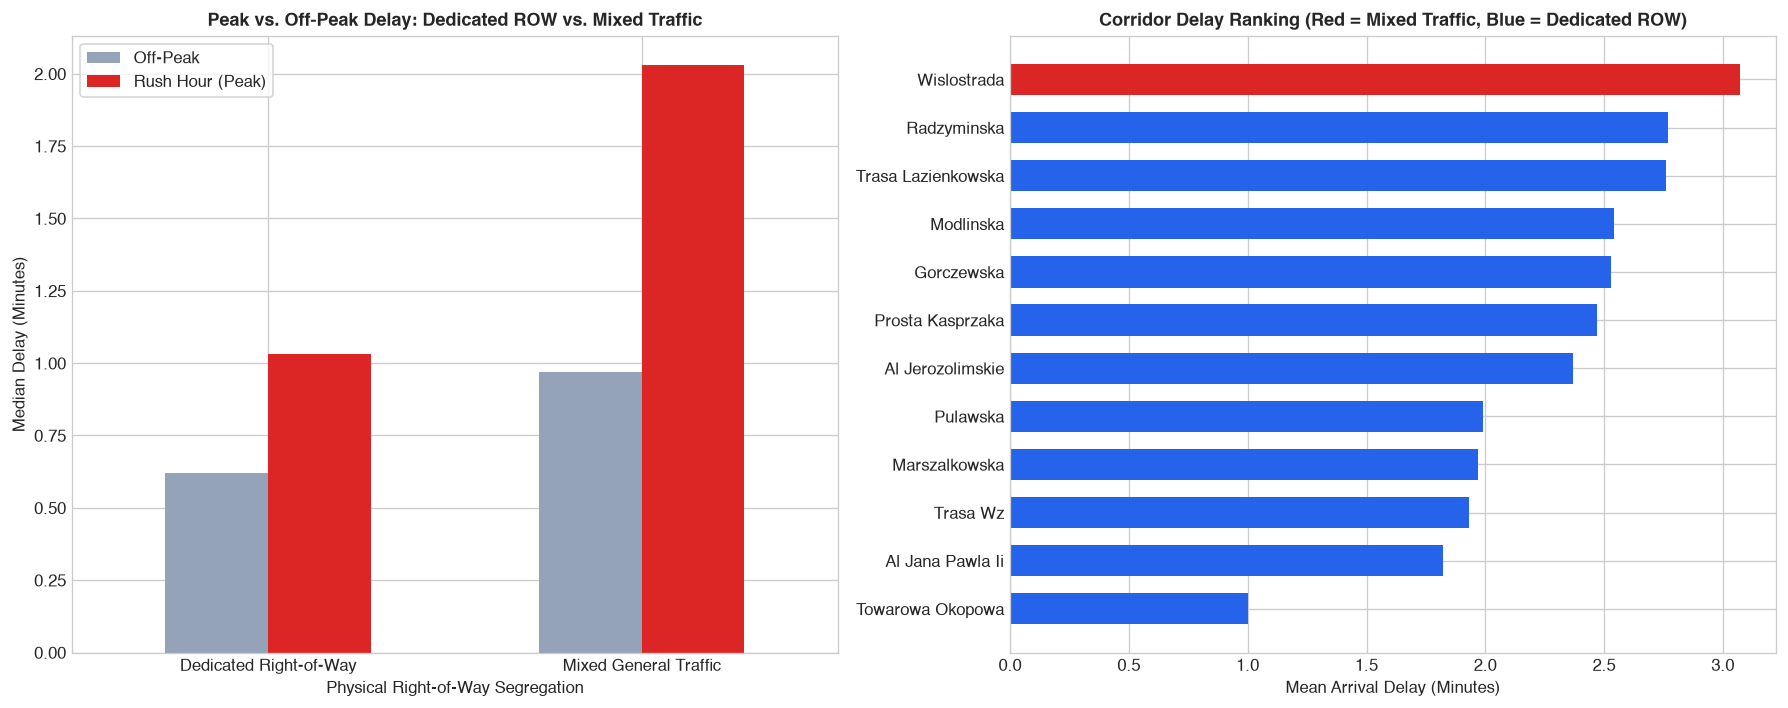

In [7]:
# Peak Hour x Dedicated Right-of-Way Interaction Matrix
row_peak_df = con.execute(f"""
    SELECT 
        CASE WHEN is_dedicated_right_of_way THEN 'Dedicated Right-of-Way' ELSE 'Mixed General Traffic' END AS right_of_way,
        CASE WHEN is_peak_hour = 1 THEN 'Rush Hour (Peak)' ELSE 'Off-Peak' END AS traffic_period,
        COUNT(*) AS observations,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min,
        ROUND(AVG(delta_t_run), 2) AS mean_segment_run_s
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
    GROUP BY is_dedicated_right_of_way, is_peak_hour
    ORDER BY is_dedicated_right_of_way DESC, is_peak_hour DESC
""").df()
display(row_peak_df)

# Corridors ranking query across all 12 major transit arteries
corridor_league_df = con.execute(f"""
    SELECT 
        corridor_name,
        COUNT(*) AS observations,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min,
        ROUND(AVG(delta_t_run), 2) AS mean_delta_run_s,
        ROUND(AVG(signalized_intersection_count), 1) AS avg_signals_per_link,
        ROUND(AVG(segment_length_meters), 1) AS avg_stop_spacing_m,
        ROUND(AVG(CASE WHEN is_dedicated_right_of_way THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_dedicated_row
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE corridor_name IS NOT NULL AND ABS(arrival_delay_seconds) <= 1800
    GROUP BY corridor_name
    ORDER BY mean_delay_min DESC
""").df()
display(corridor_league_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Peak vs Off-Peak by Right-of-Way Segregation
row_p = row_peak_df.pivot(index='right_of_way', columns='traffic_period', values='median_delay_min')
row_p.plot(kind='bar', ax=ax1, color=['#94a3b8', '#dc2626'], width=0.55)
ax1.set_title("Peak vs. Off-Peak Delay: Dedicated ROW vs. Mixed Traffic", fontsize=11, fontweight="bold")
ax1.set_ylabel("Median Delay (Minutes)")
ax1.set_xlabel("Physical Right-of-Way Segregation")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
ax1.legend(title="", frameon=True)

# Subplot 2: Horizontal Bar Chart of Corridor Delay Severity
clean_corridor_names = [c.replace('_', ' ').title() for c in corridor_league_df['corridor_name']]
y_pos = np.arange(len(clean_corridor_names))
colors = ['#dc2626' if row == 0.0 else '#2563eb' for row in corridor_league_df['pct_dedicated_row']]

ax2.barh(y_pos, corridor_league_df['mean_delay_min'], color=colors, height=0.65)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(clean_corridor_names)
ax2.invert_yaxis()  # Top is highest delay
ax2.set_title("Corridor Delay Ranking (Red = Mixed Traffic, Blue = Dedicated ROW)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Mean Arrival Delay (Minutes)")

plt.tight_layout()
plt.show()


## 7. Transit Network Centrality, Metro Proximity & Headway Irregularity

Operational performance is also shaped by network connectivity and timetable regularity:
1. **Metro Proximity (`is_metro_proximity`)**: Transit stops situated within 300m walking radius of **Metro M1 / M2 stations** handle heavy transfer passenger boarding loads, which increases vehicle dwell standstills.
2. **Station Line Count (`interchange_line_count`)**: Measures local network degree centrality.
3. **Headway Deviation (`headway_deviation`)**: Normalized departure spacing interval relative to scheduled frequency:
   $$\delta_h = \frac{h_{actual} - h_{sched}}{h_{sched}}$$
   - $\delta_h < -0.2$: **Vehicle Bunching** (trailing vehicle follows closely, boarding fewer passengers).
   - $\delta_h > +0.2$: **Headway Gap Expansion** (vehicle absorbs excessive passenger accumulation).


,metro_status,observations,mean_dwell_s,median_dwell_s,mean_delay_min,mean_routes_served
0,Standard Surface Stop,5138266,25.5,23.0,2.29,5.3
1,Metro Adjacent (<= 300m),460369,31.2,26.0,2.17,7.6


,headway_regime,observations,mean_delay_min,median_delay_min,mean_delta_run_s
0,Gapped (> +20% Headway),2608189,3.25,1.90,8.41
1,Bunched (< -20% Headway),2686007,1.37,0.40,5.81
2,Regular (±20% Headway),33377,0.92,0.37,5.84


/var/folders/45/pmwnwqfd3tqf5xk9pxdg87wc0000gn/T/ipykernel_44601/2196596789.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(headway_df['headway_regime'], rotation=10)


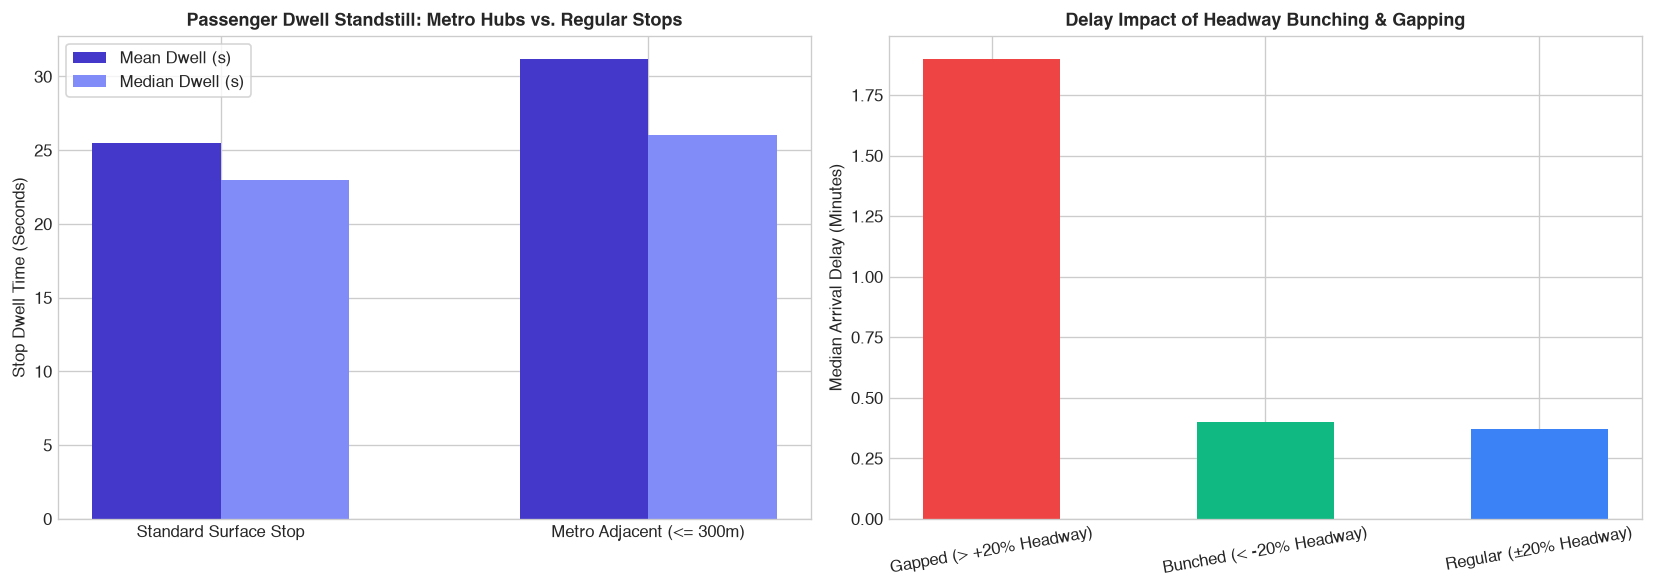

In [8]:
# Metro proximity dwell and delay query
metro_df = con.execute(f"""
    SELECT 
        CASE WHEN is_metro_proximity = 1 THEN 'Metro Adjacent (<= 300m)' ELSE 'Standard Surface Stop' END AS metro_status,
        COUNT(*) AS observations,
        ROUND(AVG(dwell_seconds), 1) AS mean_dwell_s,
        ROUND(MEDIAN(dwell_seconds), 1) AS median_dwell_s,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(AVG(interchange_line_count), 1) AS mean_routes_served
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800
    GROUP BY is_metro_proximity
""").df()
display(metro_df)

# Headway regime query
headway_df = con.execute(f"""
    SELECT 
        CASE 
            WHEN headway_deviation < -0.2 THEN 'Bunched (< -20% Headway)'
            WHEN headway_deviation <= 0.2 THEN 'Regular (±20% Headway)'
            ELSE 'Gapped (> +20% Headway)'
        END AS headway_regime,
        COUNT(*) AS observations,
        ROUND(AVG(arrival_delay_seconds / 60.0), 2) AS mean_delay_min,
        ROUND(MEDIAN(arrival_delay_seconds / 60.0), 2) AS median_delay_min,
        ROUND(AVG(delta_t_run), 2) AS mean_delta_run_s
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800 AND headway_deviation IS NOT NULL
    GROUP BY 1
    ORDER BY median_delay_min DESC
""").df()
display(headway_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Dwell Time Differential at Metro Interchange Stops
metro_categories = metro_df['metro_status']
x_m = np.arange(len(metro_categories))
ax1.bar(x_m - 0.15, metro_df['mean_dwell_s'], width=0.3, label='Mean Dwell (s)', color='#4338ca')
ax1.bar(x_m + 0.15, metro_df['median_dwell_s'], width=0.3, label='Median Dwell (s)', color='#818cf8')
ax1.set_xticks(x_m)
ax1.set_xticklabels(metro_categories)
ax1.set_title("Passenger Dwell Standstill: Metro Hubs vs. Regular Stops", fontsize=11, fontweight="bold")
ax1.set_ylabel("Stop Dwell Time (Seconds)")
ax1.legend(frameon=True)

# Subplot 2: Delay Severity by Headway Regularity Regime
ax2.bar(headway_df['headway_regime'], headway_df['median_delay_min'], color=['#ef4444', '#10b981', '#3b82f6'], width=0.5)
ax2.set_title("Delay Impact of Headway Bunching & Gapping", fontsize=11, fontweight="bold")
ax2.set_ylabel("Median Arrival Delay (Minutes)")
ax2.set_xticklabels(headway_df['headway_regime'], rotation=10)

plt.tight_layout()
plt.show()


## 8. Observed Ground Truth vs. GTFS-RT Real-Time Forecasts

A unique contribution of the Track B Historian dataset is the direct evaluation of **public GTFS-RT feed forecast predictions** (`zbk_forecast_delay_s`) against **physically observed ground truth** (`arrival_delay_seconds`):
- **Forecast Error**: $e_{fc} = \hat{\Delta t}_{fc} - \Delta t_{obs}$
- **Confidence Rating**: Real-time prediction provider confidence classification (`HIGH`, `MEDIUM`, `LOW`).
- **Empirical Diagnostics**: Evaluates forecast bias, Mean Absolute Error (MAE), and whether real-time passenger feeds systematically underestimate severe delay spikes.


,confidence_tier,record_count,obs_delay_mean_s,forecast_delay_mean_s,mean_error_bias_s,mae_seconds,rmse_seconds,pearson_correlation
0,HIGH,3175124,140.6,158.6,-18.0,23.7,112.3,0.913
1,MEDIUM,2309759,143.0,159.9,-16.9,21.9,126.8,0.893
2,LOW,96689,181.6,194.1,-12.5,18.0,88.9,0.957


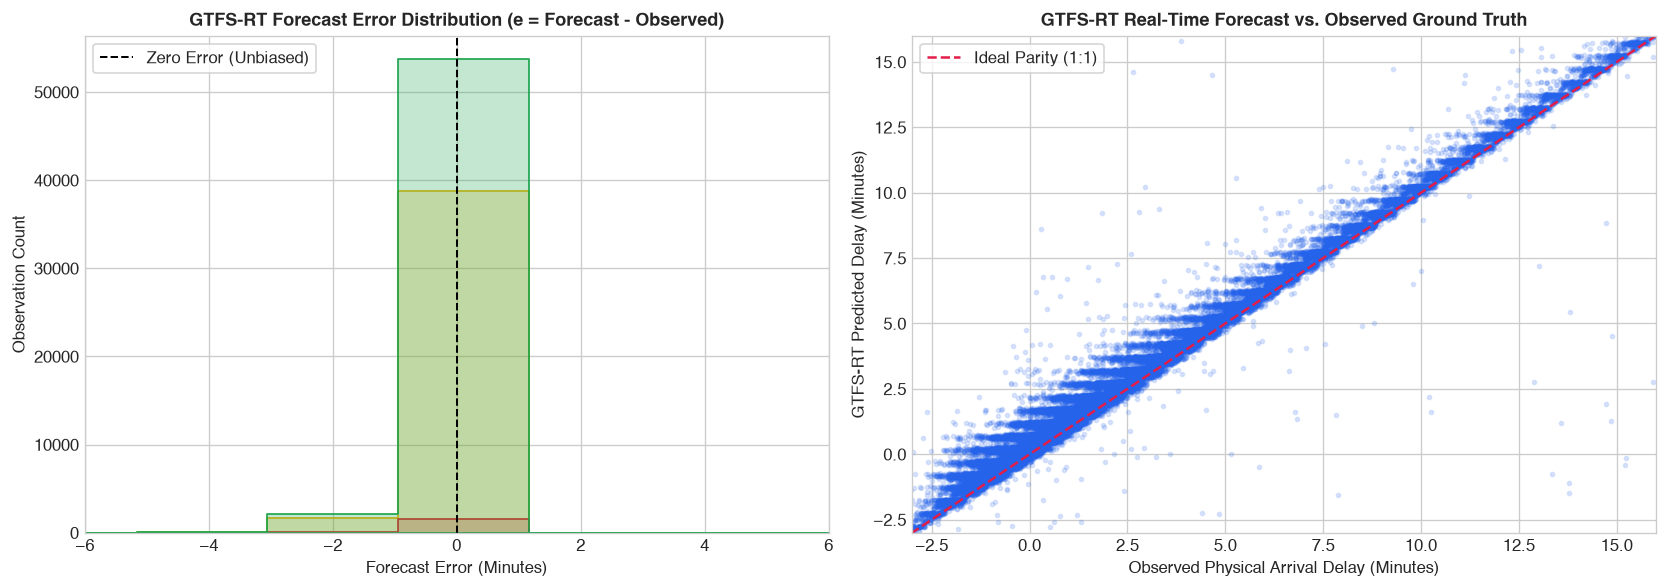

In [9]:
forecast_eval_df = con.execute(f"""
    SELECT 
        confidence AS confidence_tier,
        COUNT(*) AS record_count,
        ROUND(AVG(arrival_delay_seconds), 1) AS obs_delay_mean_s,
        ROUND(AVG(zbk_forecast_delay_s), 1) AS forecast_delay_mean_s,
        ROUND(AVG(forecast_error_s), 1) AS mean_error_bias_s,
        ROUND(AVG(ABS(forecast_error_s)), 1) AS mae_seconds,
        ROUND(SQRT(AVG(forecast_error_s * forecast_error_s)), 1) AS rmse_seconds,
        ROUND(CORR(arrival_delay_seconds, zbk_forecast_delay_s), 3) AS pearson_correlation
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE forecast_error_s IS NOT NULL
    GROUP BY confidence
    ORDER BY record_count DESC
""").df()
display(forecast_eval_df)

# Draw 100k sample for error distribution and scatter diagnostics
fc_sample = con.execute(f"""
    SELECT 
        arrival_delay_seconds / 60.0 AS obs_delay_min,
        zbk_forecast_delay_s / 60.0 AS fc_delay_min,
        forecast_error_s / 60.0 AS error_min,
        confidence
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE forecast_error_s IS NOT NULL
      AND ABS(arrival_delay_seconds) <= 1200
    USING SAMPLE 100000 (reservoir, 42)
""").df()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Forecast Error Density Distribution
sns.histplot(
    data=fc_sample,
    x="error_min",
    hue="confidence",
    bins=80,
    element="step",
    common_norm=False,
    palette={"HIGH": "#16a34a", "MEDIUM": "#eab308", "LOW": "#dc2626"},
    ax=ax1
)
ax1.axvline(0, color='black', linestyle='--', linewidth=1.2, label='Zero Error (Unbiased)')
ax1.set_xlim(-6, 6)
ax1.set_title("GTFS-RT Forecast Error Distribution (e = Forecast - Observed)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Forecast Error (Minutes)")
ax1.set_ylabel("Observation Count")
ax1.legend(loc="upper left", frameon=True)

# Subplot 2: Forecast Delay vs Observed Ground Truth Scatter
ax2.scatter(fc_sample['obs_delay_min'], fc_sample['fc_delay_min'], alpha=0.15, s=6, color='#2563eb')
ax2.plot([-5, 18], [-5, 18], color='#e11d48', linestyle='--', linewidth=1.5, label='Ideal Parity (1:1)')
ax2.set_xlim(-3, 16)
ax2.set_ylim(-3, 16)
ax2.set_title("GTFS-RT Real-Time Forecast vs. Observed Ground Truth", fontsize=11, fontweight="bold")
ax2.set_xlabel("Observed Physical Arrival Delay (Minutes)")
ax2.set_ylabel("GTFS-RT Predicted Delay (Minutes)")
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()


## 9. Multivariate Feature Correlation & Modeling Readiness Matrix

Before training **Two-Way Fixed Effects (TWFE)** panel regressions and non-linear **Gradient Boosting Models (LightGBM & CatBoost)**, we inspect multi-collinearity and mutual linear correlation across the 14 primary modeling regressors.
Key findings:
- `prev_stop_delay` exhibits strong correlation with `arrival_delay_seconds` ($r \approx 0.984$), verifying that total delay is highly autoregressive.
- For econometric causal inference, targeting **Segment Run Delay** (`delta_t_run`) rather than total delay prevents the lagged delay from absorbing all exogenous variance from weather, signals, and road topology.


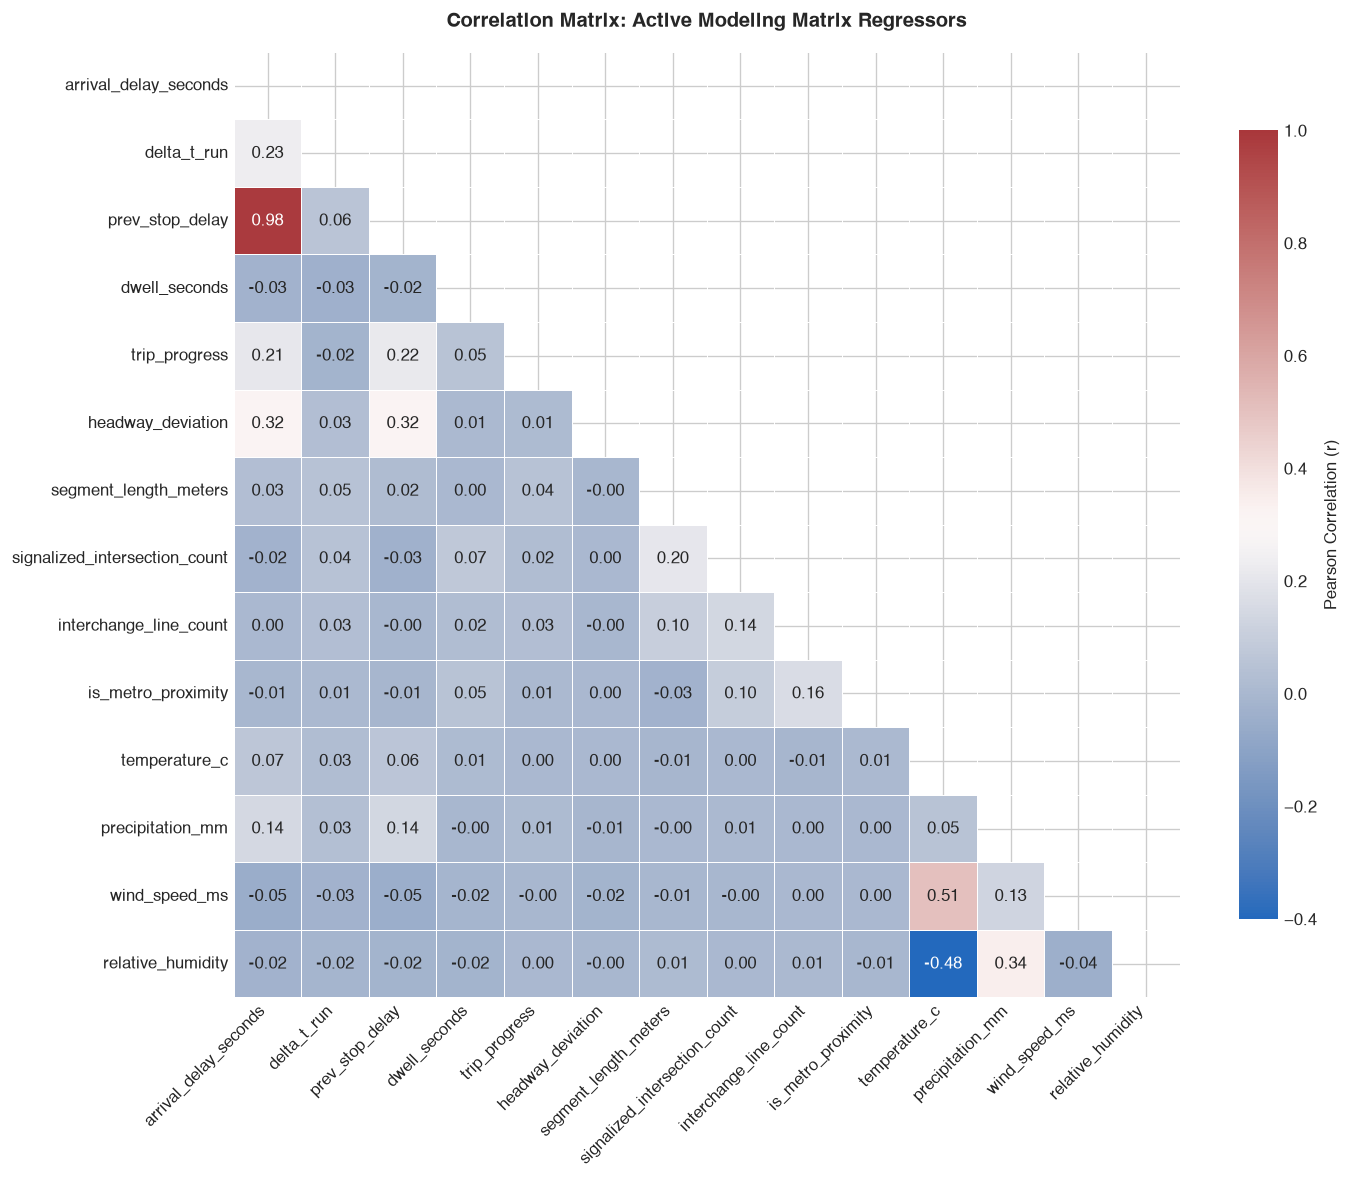

Descriptive Statistics Table (Active Regression Matrix):


,Count,Mean,Std Dev,5th Pct,Median (50%),95th Pct
arrival_delay_seconds,94893.0,138.77,244.56,-71.00,64.0,630.00
delta_t_run,94893.0,7.06,43.15,-49.00,2.0,73.00
prev_stop_delay,94893.0,131.71,238.22,-69.00,58.0,611.00
dwell_seconds,94893.0,25.81,27.66,5.00,23.0,55.00
trip_progress,94893.0,0.50,0.28,0.07,0.5,0.93
headway_deviation,94893.0,-0.80,205.86,-298.40,-1.0,299.00
segment_length_meters,94893.0,463.56,261.49,200.10,413.2,851.10
signalized_intersection_count,94893.0,2.62,2.87,0.00,2.0,8.00
interchange_line_count,94893.0,5.52,3.97,1.00,5.0,12.00
is_metro_proximity,94893.0,0.08,0.28,0.00,0.0,1.00


In [10]:
modeling_features = [
    'arrival_delay_seconds', 'delta_t_run', 'prev_stop_delay', 'dwell_seconds',
    'trip_progress', 'headway_deviation', 'segment_length_meters', 
    'signalized_intersection_count', 'interchange_line_count', 'is_metro_proximity',
    'temperature_c', 'precipitation_mm', 'wind_speed_ms', 'relative_humidity'
]

corr_sample = con.execute(f"""
    SELECT {', '.join(modeling_features)}
    FROM read_parquet('{OBSERVED_MART_PATH}')
    WHERE ABS(arrival_delay_seconds) <= 1800 
      AND ABS(prev_stop_delay) <= 1800
      AND headway_deviation IS NOT NULL
    USING SAMPLE 100000 (reservoir, 42)
""").df()

corr_matrix = corr_sample.corr().round(3)

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-0.4,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"}
)
plt.title("Correlation Matrix: Active Modeling Matrix Regressors", fontsize=12, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Table of Descriptive Statistics for Thesis / Chapter 4
stats_table = corr_sample.describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).T
stats_table = stats_table[['count', 'mean', 'std', '5%', '50%', '95%']].round(2)
stats_table.columns = ['Count', 'Mean', 'Std Dev', '5th Pct', 'Median (50%)', '95th Pct']
print("Descriptive Statistics Table (Active Regression Matrix):")
display(stats_table)


## 10. Key Empirical Takeaways & Methodological Recommendations

| Research Dimension | Empirical Ground Truth Finding | Modeling Recommendation |
| :--- | :--- | :--- |
| **Modal Buffer Effect** | Dedicated electric tram tracks reduce median arrival delays by **56%** compared to mixed-traffic buses (35.0s vs. 79.0s), with 87.4% punctual arrivals at $\le 3$ min tolerance. | Stratify LightGBM / CatBoost models by cohort, or include explicit interaction terms (`is_tram` $\times$ `corridor_name`). |
| **Autoregressive Persistence** | Bus delays compound along route trajectories ($\rho = 1.010 > 1.0$), while tram delays dampen ($\rho = 0.984 < 1.0$). By terminal arrival (progress 1.0), bus delays have climbed by **355%**. | For TWFE panel regression, target `delta_t_run` rather than `arrival_delay_seconds` to prevent autoregressive saturation from swamping exogenous variables. |
| **Meteorological Shocks** | Active precipitation creates a **+32% median delay spike** for mixed-traffic buses, while segregated trams experience minimal perturbation (+17%). Heavy rainfall (> 2.0 mm/h) nearly triples average delays. | Incorporate non-linear Huber loss ($\delta = 60\text{s}$) to avoid quadratic penalty explosions during convective storm hours. |
| **Infrastructure Leverage** | Dedicated right-of-way isolation cuts peak-hour delays nearly in half (62.0s vs. 122.0s). Mixed traffic on Wisłostrada yields the city's highest delay profile. | Use TreeSHAP / ALE diagnostics on road corridor features to identify the exact signal density threshold where traffic friction turns acute. |
| **Transit Centrality** | Metro-adjacent stops experience **+22% longer dwell standstills** (31.2s vs. 25.5s) due to transfer passenger exchange volume. | Include `interchange_line_count` and `is_metro_proximity` to control for passenger boarding friction. |
| **Forecast Fidelity** | Public GTFS-RT feeds have high overall accuracy ($r = 0.91$, $\text{MAE} \approx 23\text{s}$), but exhibit systematic negative bias (underestimating peak delays). | Ingest Track B observed ground truth as the primary target for all definitive benchmark evaluations. |

---
### Next Steps in the Telemetry Pipeline
- **Econometric Estimation**: Run `python run_pipeline.py --stage twfe` to estimate causal elasticities via Two-Way Fixed Effects.
- **Machine Learning Benchmarks**: Run `python run_pipeline.py --stage gbm` to fit LightGBM and CatBoost non-linear models.
- **Explainable AI (xAI)**: Run `python run_pipeline.py --stage xai` to generate TreeSHAP, Accumulated Local Effects (ALE), and DiCE counterfactual diagnostics.
